In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv('merged_cleaned_FE_data_v2.csv')

In [6]:
df.sample(5)

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,...,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
335,flat,dlf new town heights,sector 86,1.27,6580.0,1930.0,Super Built up area 1930(179.3 sq.m.)Built Up ...,3,4,3,...,1800.0,1450.0,1,0,1,0,0,0,126,15
2654,flat,godrej summit,sector 104,1.10,8669.0,1269.0,Super Built up area 1269(117.89 sq.m.),2,2,3,...,NaN,NaN,0,0,0,0,1,0,88,15
2407,flat,ats triumph,sector 104,1.83,7991.0,2290.0,Super Built up area 2290(212.75 sq.m.)Built Up...,3,4,3+,...,2000.0,1750.0,0,0,1,0,0,0,165,14
378,house,independent,sector 38,4.00,21786.0,1836.0,Plot area 204(170.57 sq.m.),6,6,3+,...,1836.0,NaN,1,1,1,0,1,1,137,47
3288,flat,godrej oasis,sector 88a,1.29,7800.0,1654.0,Super Built up area 1629(151.34 sq.m.)Carpet a...,3,3,3,...,NaN,1628.0,0,1,0,0,1,0,65,7


In [7]:
df.shape

(3799, 24)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3799 entries, 0 to 3798
Data columns (total 24 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   property_type         3799 non-null   object 
 1   society               3798 non-null   object 
 2   sector                3799 non-null   object 
 3   price                 3782 non-null   float64
 4   price_per_sqft        3782 non-null   float64
 5   area                  3782 non-null   float64
 6   areaWithType          3799 non-null   object 
 7   bedRoom               3799 non-null   int64  
 8   bathroom              3799 non-null   int64  
 9   balcony               3799 non-null   object 
 10  floorNum              3781 non-null   float64
 11  facing                2697 non-null   object 
 12  agePossession         3799 non-null   object 
 13  super_built_up_area   1915 non-null   float64
 14  built_up_area         1730 non-null   float64
 15  carpet_area          

In [9]:
df.duplicated().sum()

np.int64(122)

In [11]:
df.drop_duplicates(inplace=True)

## Price column analysis

In [12]:
df['price'].isnull().sum()

np.int64(16)

In [13]:
df['price'].describe()

count    3661.000000
mean        2.534464
std         2.979951
min         0.070000
25%         0.950000
50%         1.530000
75%         2.750000
max        31.500000
Name: price, dtype: float64

<Axes: xlabel='price', ylabel='Count'>

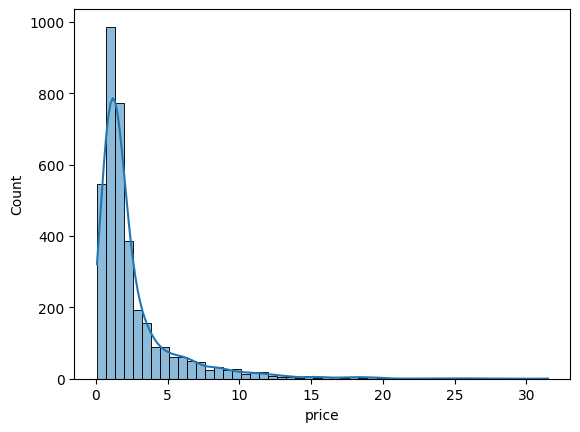

In [14]:
sns.histplot(df['price'], kde=True, bins=50)

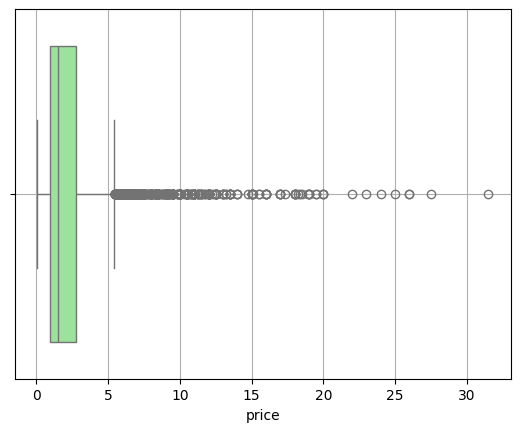

In [15]:
sns.boxplot(x=df['price'], color='lightgreen')
plt.grid()

#### Descriptive Statistics

- **Count:** There are 3,661 non-missing price entries.
- **Mean Price:** The average price is approximately 2.53 crores.
- **Median Price:** The median (50th percentile) price is 1.53 crores.
- **Standard Deviation:** The prices have a standard deviation of 2.98, indicating variability in the prices.
- **Range:** Prices range from a minimum of 0.07 crores to a maximum of 31.5 crores.
- **IQR:** The interquartile range (difference between 75th and 25th percentile) is from 0.95 crores to 2.75 crores.

#### Visualizations

- **Distribution:** The histogram indicates that most properties are priced in the lower range (below 5 crores), with a few properties going beyond 10 crores.
- **Box Plot:** The box plot showcases the spread of the data and potential outliers. Properties priced above approximately 10 crores might be considered outliers as they lie beyond the upper whisker of the box plot.

#### Missing Values

- There are 16 missing values in the price column.

In [18]:
# Skewness and Kurtosis
skewness = df['price'].skew()
kurtosis = df['price'].kurt()

print(skewness,kurtosis)

3.279799523686265 14.941068438459675


In [19]:
# Skewness:
# The price distribution has a skewness of approximately 3.28, indicating a positive skew. 
# This means that the distribution tail is skewed to the right, which aligns with our observation from the 
# histogram where most properties have prices on the lower end with a few high-priced properties.

# Kurtosis: 
# The kurtosis value is approximately 14.93. A kurtosis value greater than 3 indicates a distribution with 
# heavier tails and more outliers compared to a normal distribution.

In [20]:
# Quantile Analysis
quantiles = df['price'].quantile([0.01, 0.05, 0.95, 0.99])

quantiles

0.01     0.25
0.05     0.37
0.95     8.50
0.99    15.26
Name: price, dtype: float64

Quantile Analysis
- 1% Quantile: 1% of properties cost below 0.25 crores.
- 5% Quantile: 5% cost below 0.37 crores.
- 95% Quantile: 95% cost below 8.5 crores.
- 99% Quantile: 99% cost below 15.26 crores.

In [21]:
# Identify potential outliers using IQR method
Q1 = df['price'].describe()['25%']
Q3 = df['price'].describe()['75%']
IQR = Q3 - Q1

IQR

np.float64(1.8)

In [22]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(lower_bound, upper_bound)

-1.7500000000000002 5.45


In [23]:
outliers = df[(df['price'] < lower_bound) | (df['price'] > upper_bound)]
outliers.shape

(425, 24)

In [24]:
outliers['price'].describe()

count    425.000000
mean       9.235624
std        4.065259
min        5.460000
25%        6.460000
50%        8.000000
75%       10.750000
max       31.500000
Name: price, dtype: float64

### Outliers Analysis (using IQR method):

- Based on the IQR method, there are 425 properties considered as outliers.
- These outliers have an average price of approximately 9.235 crores.
- The range for these outliers is from 5.46 crores to 31.5 crores.

<Axes: xlabel='price'>

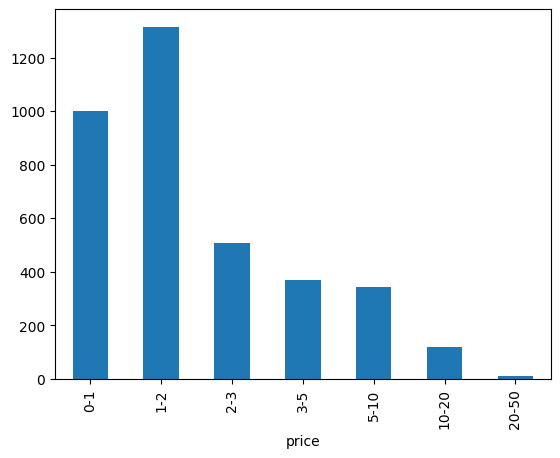

In [25]:
# price binning
bins = [0, 1, 2, 3, 5, 10, 20, 50]
bin_labels = ["0-1", "1-2", "2-3", "3-5", "5-10", "10-20", "20-50"]
pd.cut(df['price'], bins=bins, labels=bin_labels, right=False).value_counts().sort_index().plot(kind='bar')

-The majority of properties are priced in the "1-2 crores" and "2-3 crores" ranges.
-There's a significant drop in the number of properties priced above "5 crores."

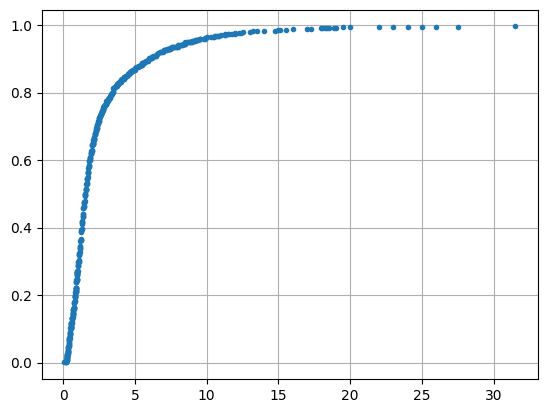

In [26]:
# ecdf plot
ecdf = df['price'].value_counts().sort_index().cumsum() / len(df['price'])
plt.plot(ecdf.index, ecdf, marker='.', linestyle='none')
plt.grid()

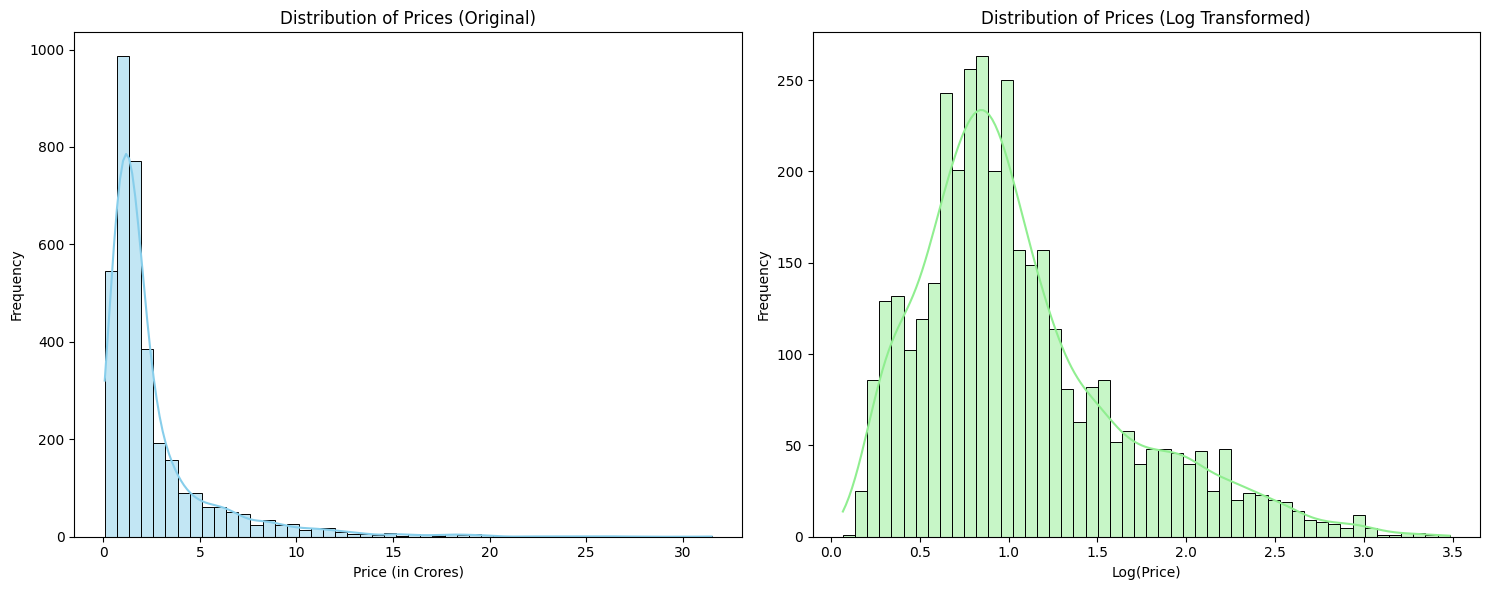

In [27]:
plt.figure(figsize=(15, 6))

# Distribution plot without log transformation
plt.subplot(1, 2, 1)
sns.histplot(df['price'], kde=True, bins=50, color='skyblue')
plt.title('Distribution of Prices (Original)')
plt.xlabel('Price (in Crores)')
plt.ylabel('Frequency')

# Distribution plot with log transformation
plt.subplot(1, 2, 2)
sns.histplot(np.log1p(df['price']), kde=True, bins=50, color='lightgreen')
plt.title('Distribution of Prices (Log Transformed)')
plt.xlabel('Log(Price)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

np.log1p(x): This function computes the natural logarithm of 1+x. It's designed to provide more accurate results for values of x that are very close to zero.

Using np.log1p helps in transforming the price column while ensuring that any value (including zero, if present) is handled appropriately. When we need to reverse the transformation, we can use np.expm1 which computes e^x-1

In [28]:
skewness = np.log1p(df['price']).skew()
kurtosis = np.log1p(df['price']).kurt()

print(skewness,kurtosis)

1.0731981145827196 0.965122007352643


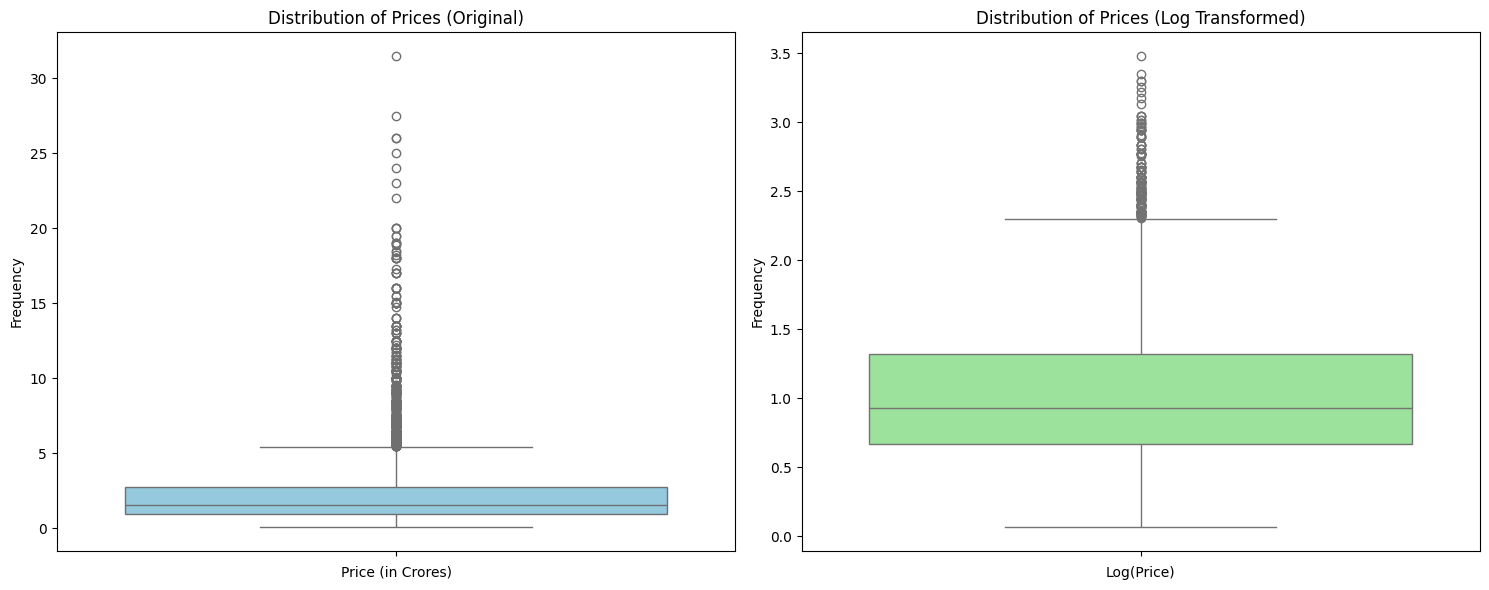

In [29]:
plt.figure(figsize=(15, 6))

# Distribution plot without log transformation
plt.subplot(1, 2, 1)
sns.boxplot(df['price'], color='skyblue')
plt.title('Distribution of Prices (Original)')
plt.xlabel('Price (in Crores)')
plt.ylabel('Frequency')

# Distribution plot with log transformation
plt.subplot(1, 2, 2)
sns.boxplot(np.log1p(df['price']), color='lightgreen')
plt.title('Distribution of Prices (Log Transformed)')
plt.xlabel('Log(Price)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

## Property_type column Analysis

<Axes: xlabel='property_type'>

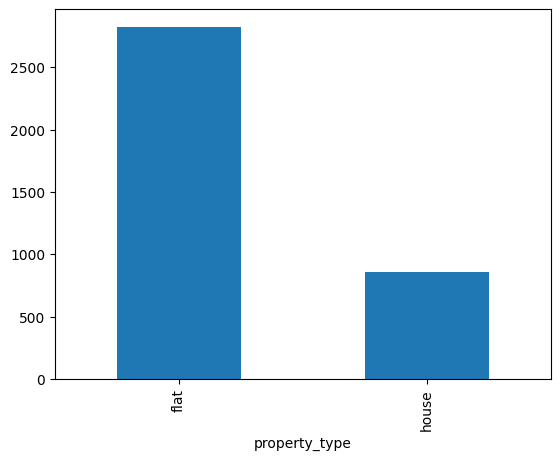

In [30]:
df['property_type'].value_counts().plot(kind='bar',)

#### Observations
Flats are in majority(75 percent) and there are less number of houses(~25 percent)
No missing values

## Society column Analysis

In [31]:
df['society'].value_counts().shape

(675,)

In [33]:
df['society'].value_counts()

society
independent                             483
tulip violet                             75
ss the leaf                              73
dlf new town heights                     42
shapoorji pallonji joyville gurugram     42
                                       ... 
sbr apartment                             1
maa bhagwati residency                    1
dlf trinity towers                        1
lotus elise                               1
park view apartments                      1
Name: count, Length: 675, dtype: int64

In [34]:
df[df['society'] != 'independent']['society'].value_counts(normalize=True).cumsum().head(75)

society
tulip violet                            0.023489
ss the leaf                             0.046351
dlf new town heights                    0.059505
shapoorji pallonji joyville gurugram    0.072659
signature global park                   0.083620
                                          ...   
ansal heights 86                        0.490448
ramsons kshitij                         0.494519
puri emerald bay                        0.498591
indiabulls enigma                       0.502662
ireo the corridors                      0.506420
Name: proportion, Length: 75, dtype: float64

In [35]:
society_counts = df['society'].value_counts()

# Frequency distribution for societies
frequency_bins = {
    "Very High (>100)": (society_counts > 100).sum(),
    "High (50-100)": ((society_counts >= 50) & (society_counts <= 100)).sum(),
    "Average (10-49)": ((society_counts >= 10) & (society_counts < 50)).sum(),
    "Low (2-9)": ((society_counts > 1) & (society_counts < 10)).sum(),
    "Very Low (1)": (society_counts == 1).sum()
}
frequency_bins

{'Very High (>100)': np.int64(1),
 'High (50-100)': np.int64(2),
 'Average (10-49)': np.int64(92),
 'Low (2-9)': np.int64(273),
 'Very Low (1)': np.int64(307)}

<Axes: xlabel='society'>

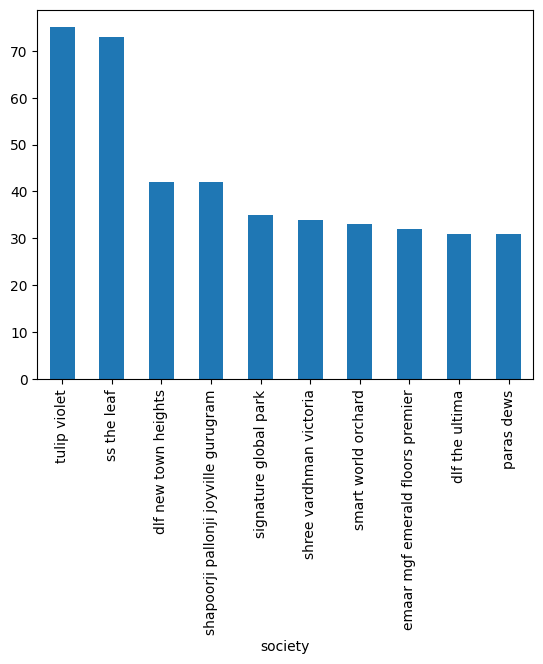

In [36]:
# top 10 socities
df[df['society'] != 'independent']['society'].value_counts().head(10).plot(kind='bar')

In [37]:
df['society'].isnull().sum()

np.int64(1)

In [38]:
df[df['society'].isnull()]

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,...,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
3105,flat,NaN,sector 78,0.6,3692.0,1625.0,Built Up area: 1625 (150.97 sq.m.),2,2,0,...,1625.0,NaN,0,0,0,0,0,0,0,0


#### Observations

- Around 13% properties come under the independent tag.
- There are 675 societies.
- The top 75 societies have 50 percent of the properties, and the remaining 50 percent come under the other 600 societies.
  - **Very High (>100):** Only 1 society has more than 100 listings.
  - **High (50-100):** 2 societies have between 50 to 100 listings.
  - **Average (10-49):** 92 societies fall in this range with 10 to 49 listings each.
  - **Low (2-9):** 273 societies have between 2 to 9 listings.
  - **Very Low (1):** A significant number, 307 societies, have only 1 listing.
- 1 missing value.

## Sector column analysis

In [39]:
# unique sectors
df['sector'].value_counts().shape

(113,)

<Axes: xlabel='sector'>

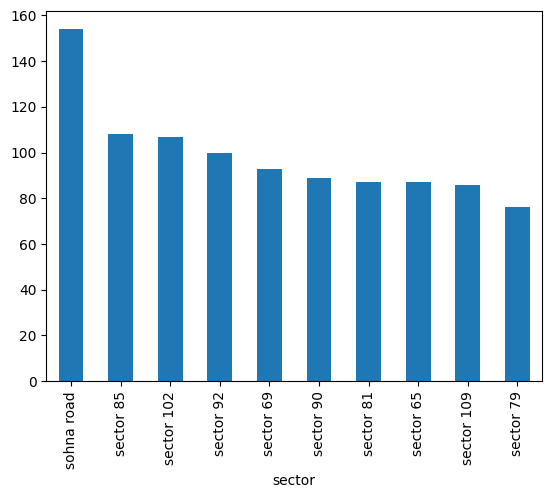

In [40]:
# top 10 sectors
df['sector'].value_counts().head(10).plot(kind='bar')

In [41]:
# Frequency distribution for sectors
sector_counts = df['sector'].value_counts()

sector_frequency_bins = {
    "Very High (>100)": (sector_counts > 100).sum(),
    "High (50-100)": ((sector_counts >= 50) & (sector_counts <= 100)).sum(),
    "Average (10-49)": ((sector_counts >= 10) & (sector_counts < 50)).sum(),
    "Low (2-9)": ((sector_counts > 1) & (sector_counts < 10)).sum(),
    "Very Low (1)": (sector_counts == 1).sum()
}

sector_frequency_bins

{'Very High (>100)': np.int64(3),
 'High (50-100)': np.int64(25),
 'Average (10-49)': np.int64(62),
 'Low (2-9)': np.int64(22),
 'Very Low (1)': np.int64(1)}

#### Observations

- There are a total of 104 unique sectors in the dataset.
- Frequency distribution of sectors:
  - Very High (>100): 3 sectors have more than 100 listings.
  - High (50-100): 25 sectors have between 50 to 100 listings.
  - Average (10-49): A majority, 62 sectors, fall in this range with 10 to 49 listings each.
  - Low (2-9): 22 sectors have between 2 to 9 listings.
  - Very Low (1): there is only 1 sector with only 1 listing.

## price_per_sqft column Analysis

In [43]:
df['price_per_sqft'].isnull().sum()

np.int64(16)

In [44]:
df['price_per_sqft'].describe()

count      3661.000000
mean      13890.033871
std       23205.624814
min           4.000000
25%        6818.000000
50%        9020.000000
75%       13888.000000
max      600000.000000
Name: price_per_sqft, dtype: float64

<Axes: xlabel='price_per_sqft', ylabel='Count'>

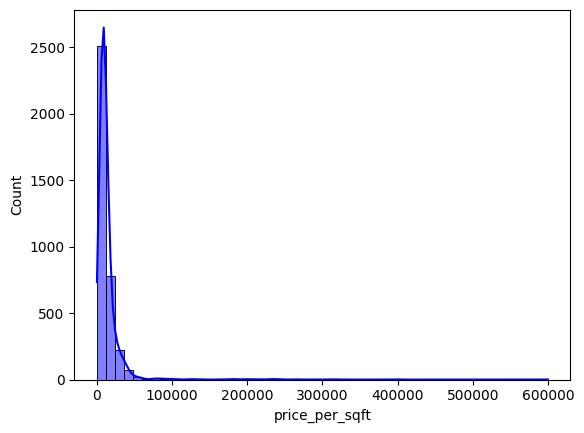

In [45]:
sns.histplot(df['price_per_sqft'], bins=50, color='blue', kde=True)

Most properties have a price_per_sqft ranging between approximately ₹0 and ₹40,000. There is a significant concentration in the lower range, with a few properties having exceptionally high price_per_sqft.

<Axes: ylabel='price_per_sqft'>

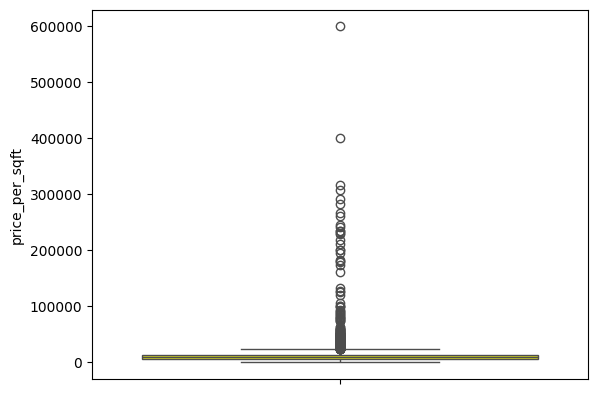

In [46]:
sns.boxplot(df['price_per_sqft'], color='yellow')

The box plot clearly shows several outliers, especially on the higher side. The interquartile range (IQR) is relatively compact, but there are many data points beyond the "whiskers" of the box plot, indicating potential outliers.

#### Observations

- Potential Outliers
- Right Skewed
- 16 missing values

## BedRoom column Analysis

In [48]:
df['bedRoom'].isnull().sum()

np.int64(0)

<Axes: xlabel='bedRoom'>

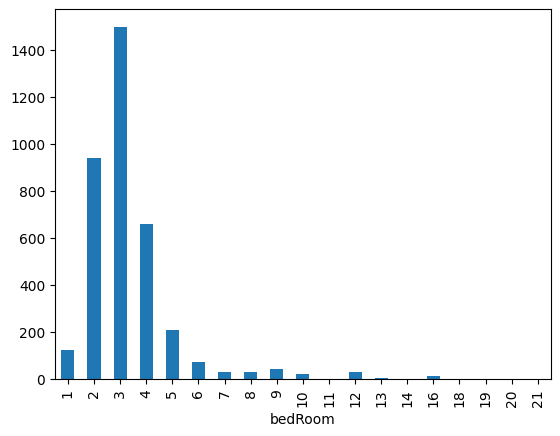

In [49]:
df['bedRoom'].value_counts().sort_index().plot(kind='bar')

<Axes: ylabel='proportion'>

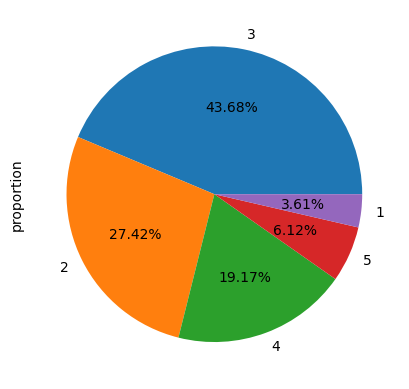

In [50]:
df['bedRoom'].value_counts(normalize=True).head().plot(kind='pie',autopct='%0.2f%%')

## Bathroom Column Analysis

In [51]:
df['bathroom'].isnull().sum()

np.int64(0)

<Axes: xlabel='bathroom'>

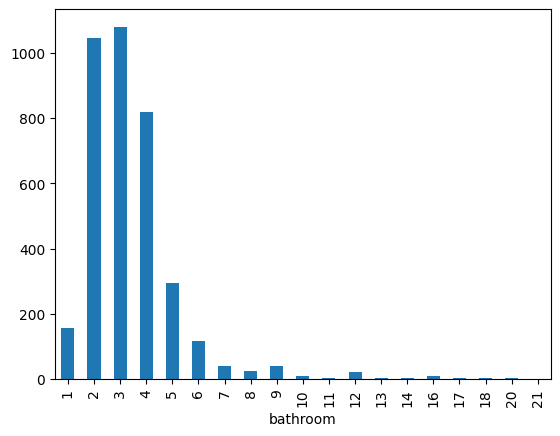

In [52]:
df['bathroom'].value_counts().sort_index().plot(kind='bar')

<Axes: ylabel='proportion'>

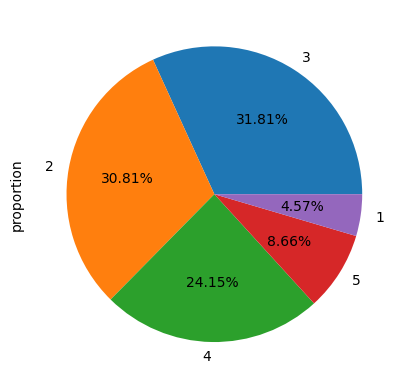

In [53]:
df['bathroom'].value_counts(normalize=True).head().plot(kind='pie',autopct='%0.2f%%')

## balcony column Analysis

In [54]:
df['balcony'].isnull().sum()

np.int64(0)

<Axes: xlabel='balcony'>

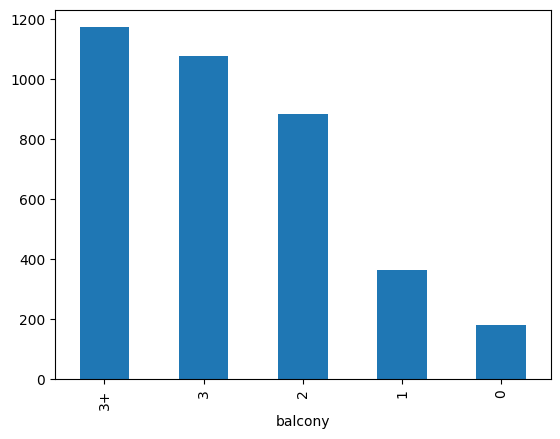

In [55]:
df['balcony'].value_counts().plot(kind='bar')

<Axes: ylabel='proportion'>

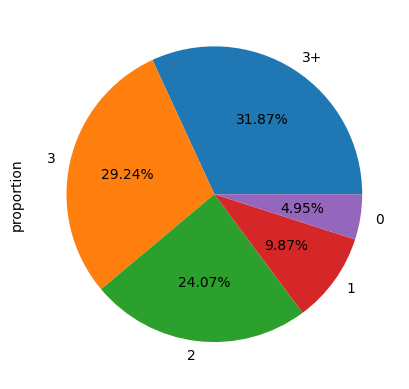

In [56]:
df['balcony'].value_counts(normalize=True).head().plot(kind='pie',autopct='%0.2f%%')

## floorNum analysis

In [57]:
df['floorNum'].isnull().sum()

np.int64(18)

In [58]:
df['floorNum'].describe()

count    3659.000000
mean        6.799399
std         6.018351
min         0.000000
25%         2.000000
50%         5.000000
75%        10.000000
max        51.000000
Name: floorNum, dtype: float64

<Axes: xlabel='floorNum'>

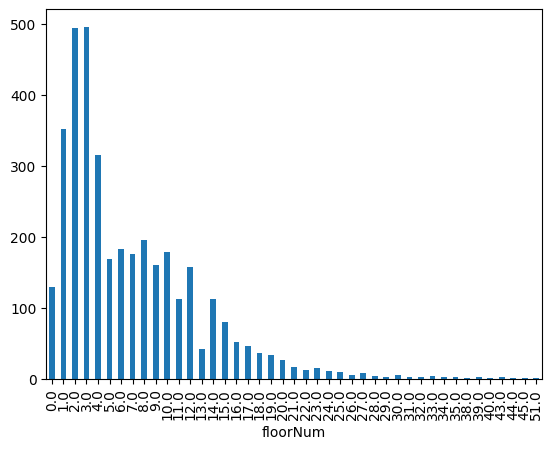

In [59]:
df['floorNum'].value_counts().sort_index().plot(kind='bar')

<Axes: ylabel='floorNum'>

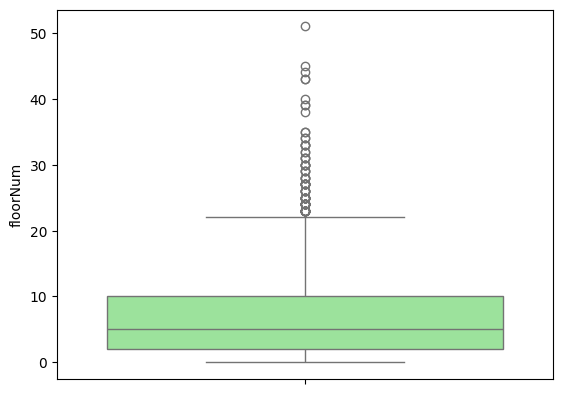

In [60]:
sns.boxplot(df['floorNum'], color='lightgreen')

- The majority of the properties lie between the ground floor (0) and the 25th floor.
- Floors 1 to 4 are particularly common, with the 3rd floor being the most frequent.
- There are a few properties located at higher floors, but their frequency is much lower.
- The box plot reveals that the majority of the properties are concentrated around the lower floors. The interquartile range (IQR) lies between approximately the 2nd and 10th floors.
- Data points beyond the "whiskers" of the box plot, especially on the higher side, indicate potential outliers.

## facing column Analysis

In [62]:
df['facing'].isnull().sum()

np.int64(1045)

In [63]:
df['facing'].fillna('NA',inplace=True)

C:\Users\THARUN TEJA S\AppData\Local\Temp\ipykernel_57544\3692945726.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['facing'].fillna('NA',inplace=True)


In [64]:
df['facing'].value_counts()

facing
NA            1045
East           623
North-East     623
North          387
West           249
South          231
North-West     193
South-East     173
South-West     153
Name: count, dtype: int64

## agePossession column Analysis

In [65]:
df['agePossession'].isnull().sum()

np.int64(0)

In [66]:
df['agePossession'].value_counts()

agePossession
Relatively New        1645
New Property           593
Moderately Old         562
Undefined              448
Old Property           303
Under Construction     126
Name: count, dtype: int64

## Areas columns Analysis

In [68]:
# super built up area
df['super_built_up_area'].isnull().sum()

np.int64(1801)

In [69]:
df['super_built_up_area'].describe()

count     1876.000000
mean      1924.557862
std        764.535501
min         89.000000
25%       1478.750000
50%       1828.000000
75%       2215.000000
max      10000.000000
Name: super_built_up_area, dtype: float64

<Axes: xlabel='super_built_up_area', ylabel='Count'>

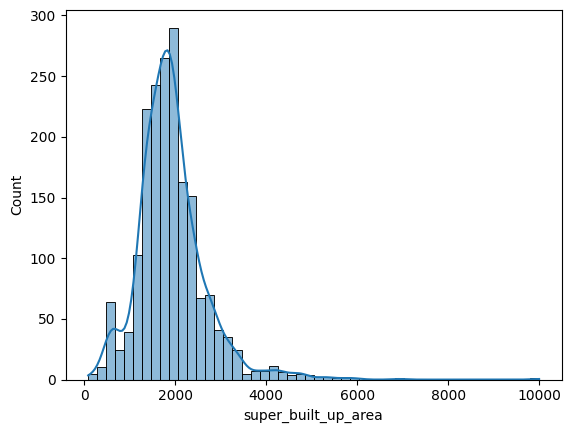

In [70]:
sns.histplot(df['super_built_up_area'].dropna(), bins=50, kde=True)

<Axes: ylabel='super_built_up_area'>

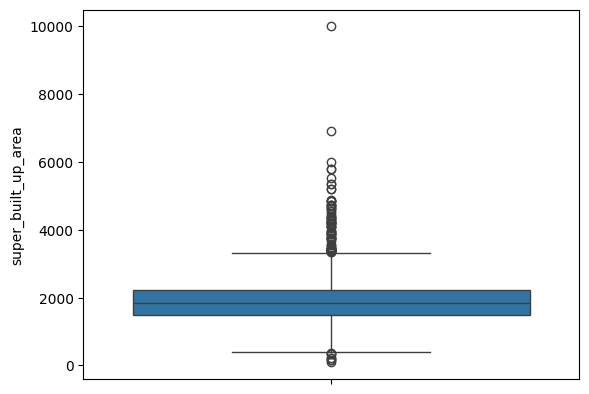

In [71]:
sns.boxplot(df['super_built_up_area'].dropna())

- Most properties have a super built-up area ranging between approximately 1,000 sq.ft and 2,500 sq.ft.
- There are a few properties with a significantly larger area, leading to a right-skewed distribution.
- The interquartile range (IQR) lies between roughly 1,480 sq.ft and 2,215 sq.ft, indicating that the middle 50% of the properties fall within this range.
- There are several data points beyond the upper "whisker" of the box plot, indicating potential outliers. These are properties with an unusually large super built-up area.

In [72]:
# built up area
df['built_up_area'].isnull().sum()

np.int64(1988)

In [73]:
df['built_up_area'].describe()


count      1689.000000
mean       2381.892261
std       17948.047434
min           2.000000
25%        1103.000000
50%        1650.000000
75%        2400.000000
max      737147.000000
Name: built_up_area, dtype: float64

<Axes: xlabel='built_up_area', ylabel='Count'>

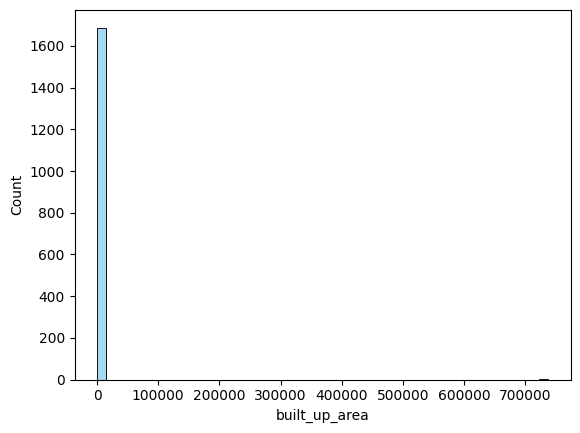

In [74]:
sns.histplot(df['built_up_area'].dropna(), bins=50, color='skyblue', kde=False)

<Axes: ylabel='built_up_area'>

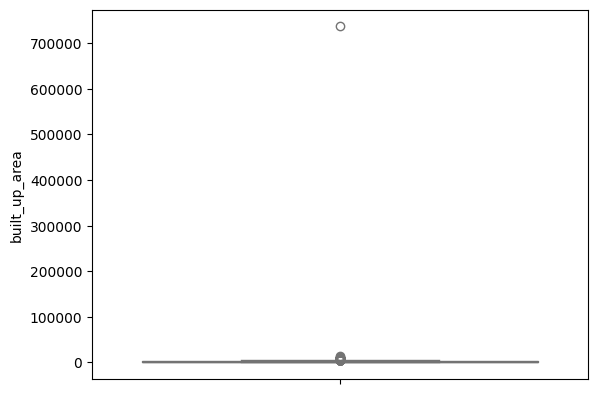

In [75]:
sns.boxplot(df['built_up_area'].dropna(), color='lightgreen')

- Most properties have a built-up area ranging roughly between 500 sq.ft and 3,500 sq.ft.
- There are very few properties with a much larger built-up area, leading to a highly right-skewed distribution.
- The box plot confirms the presence of significant outliers on the higher side. The data's interquartile range (IQR) is relatively compact, but the "whiskers" of the box plot are stretched due to the outliers.

The presence of extreme values, especially on the higher side, suggests that there may be outliers or data errors. This could also be due to some properties being exceptionally large, like a commercial complex or an entire building being listed.

In [76]:
# carpet area
df['carpet_area'].isnull().sum()

np.int64(1804)

In [77]:
df['carpet_area'].describe()

count      1873.000000
mean       2529.394489
std       22793.715742
min          15.000000
25%         845.000000
50%        1300.000000
75%        1790.000000
max      607936.000000
Name: carpet_area, dtype: float64

<Axes: xlabel='carpet_area', ylabel='Count'>

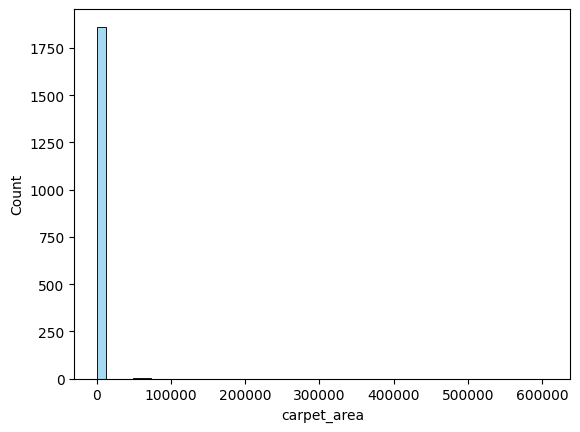

In [78]:
sns.histplot(df['carpet_area'].dropna(), bins=50, color='skyblue', kde=False)

<Axes: ylabel='carpet_area'>

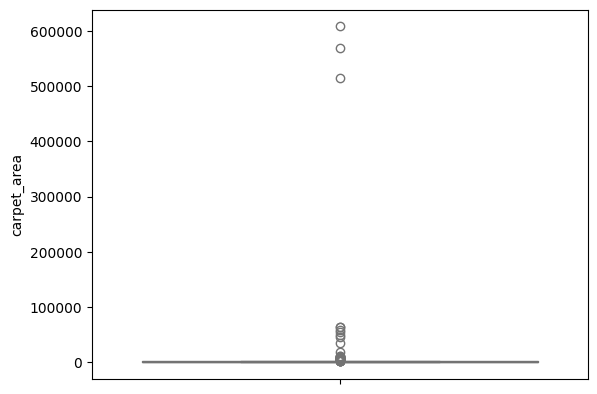

In [79]:
sns.boxplot(df['carpet_area'].dropna(), color='lightgreen')

In [80]:
df.iloc[:,16:]

,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
0,0,0,0,0,0,0,30,6
1,0,0,0,0,0,0,49,47
2,1,0,1,0,0,0,65,6
3,1,1,1,0,1,0,166,47
4,0,0,0,0,0,1,44,8
...,...,...,...,...,...,...,...,...
3794,0,0,0,0,0,0,174,10
3795,1,0,1,0,0,0,21,48
3796,0,0,0,0,0,0,46,49
3797,0,0,1,0,0,0,33,0


## AdditionalRooms Analysis

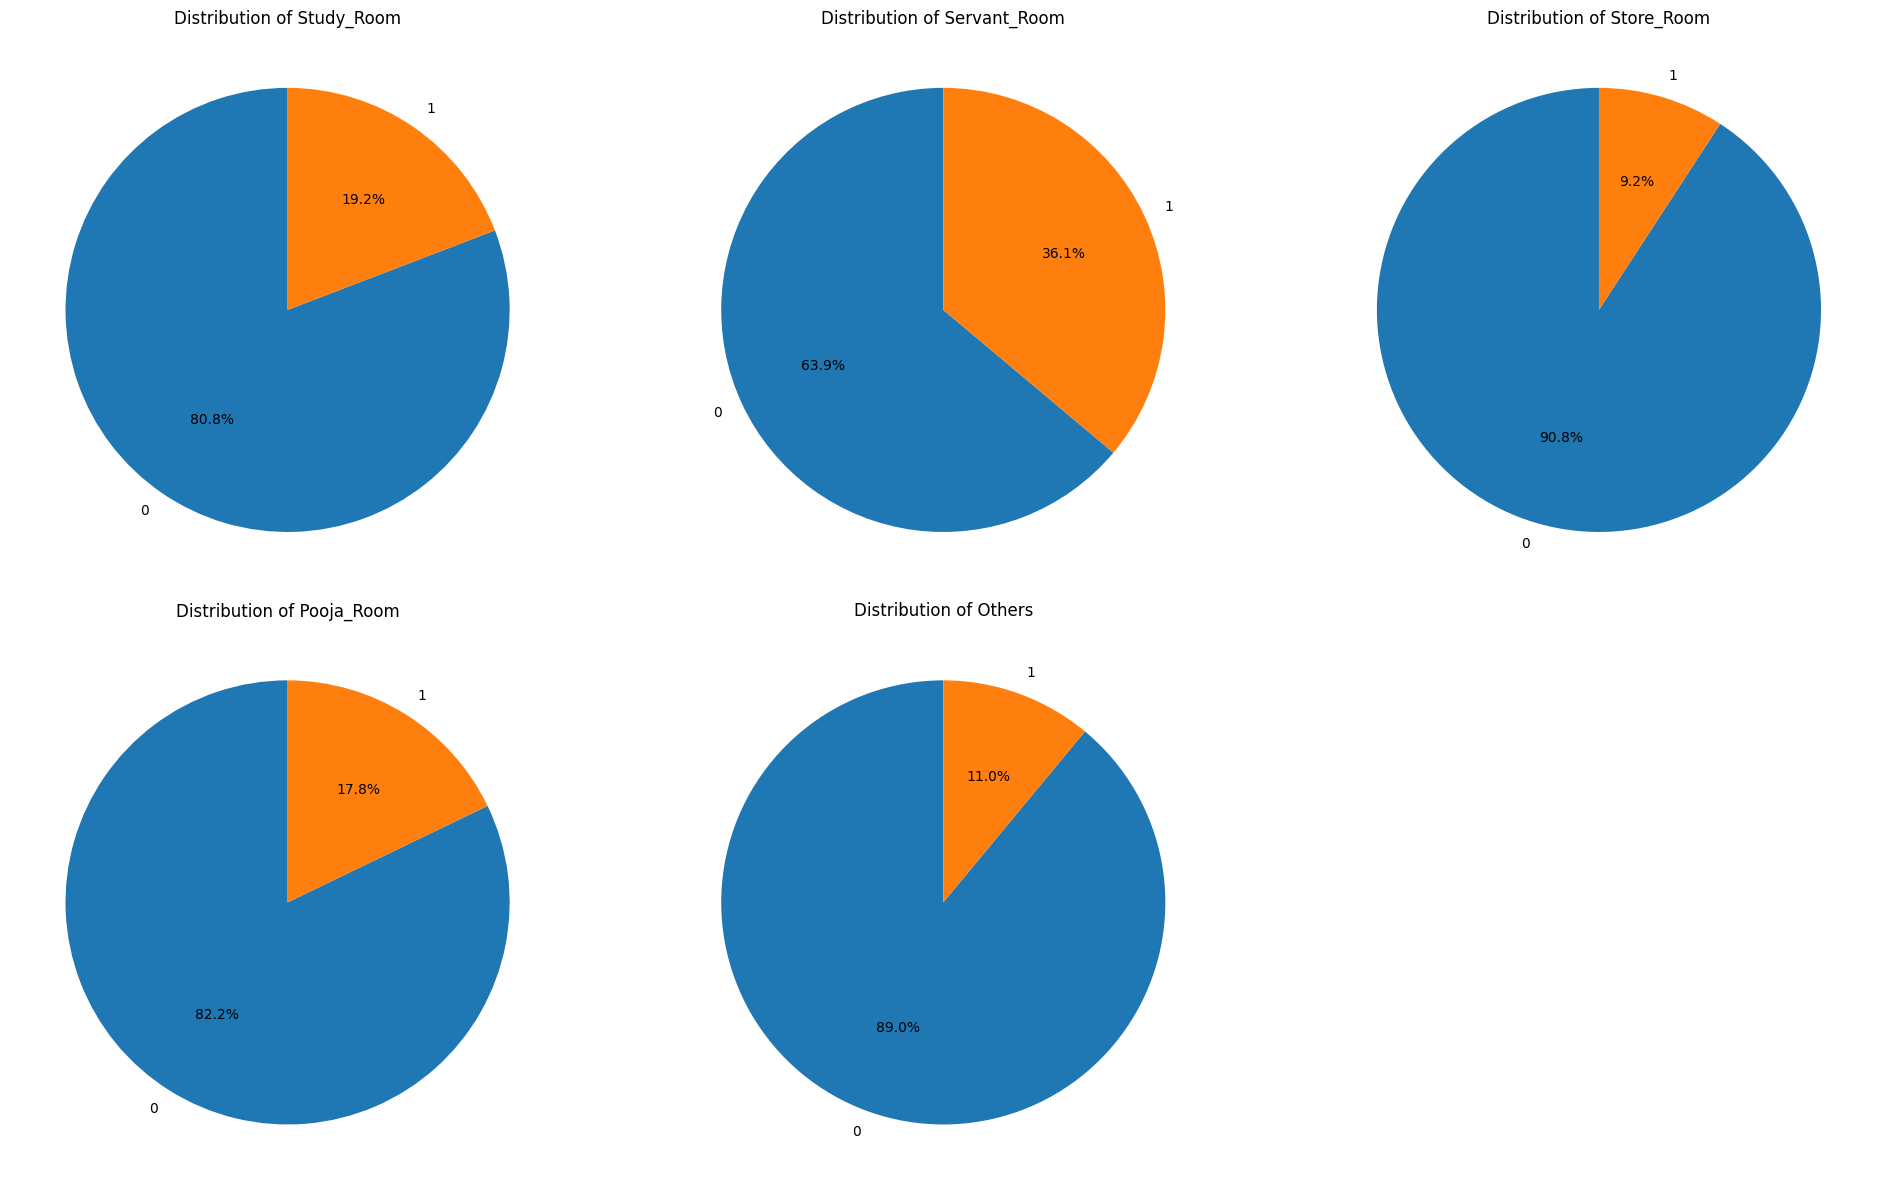

In [83]:
plt.figure(figsize=(20, 12))

# Create a subplot of pie charts for each room type
for idx, room in enumerate(['study_room','servant_room','store_room','pooja_room','others'], 1):
    ax = plt.subplot(2, 3, idx)
    df[room].value_counts().plot.pie(autopct='%1.1f%%', startangle=90, ax=ax)
    plt.title(f'Distribution of {room.title()}')
    plt.ylabel('')

plt.tight_layout()
plt.show()

## furnishing_type Analysis

In [84]:
df['furnishing_type'].value_counts()

furnishing_type
0    3293
1     383
2       1
Name: count, dtype: int64

<Axes: ylabel='count'>

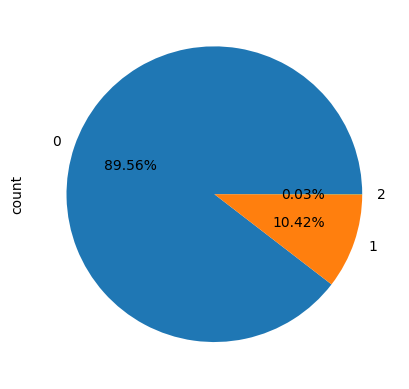

In [85]:
df['furnishing_type'].value_counts().plot(kind='pie',autopct='%0.2f%%')

## luxury score Analysis

In [86]:
df['luxury_score'].isnull().sum()

np.int64(0)

In [87]:
df['luxury_score'].describe()

count    3677.000000
mean       71.545553
std        53.023563
min         0.000000
25%        31.000000
50%        59.000000
75%       110.000000
max       174.000000
Name: luxury_score, dtype: float64

<Axes: xlabel='luxury_score', ylabel='Count'>

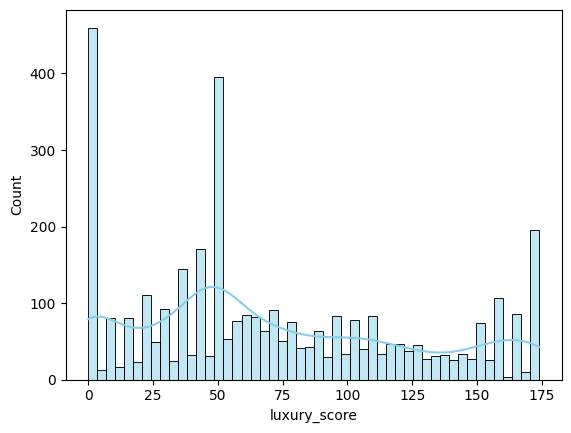

In [88]:
sns.histplot(df['luxury_score'], bins=50, color='skyblue', kde=True)

<Axes: ylabel='luxury_score'>

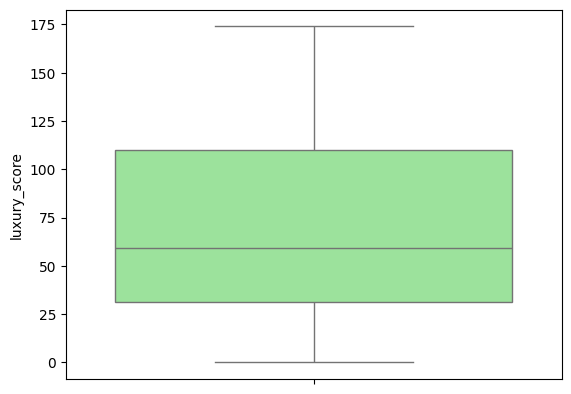

In [89]:
sns.boxplot(df['luxury_score'], color='lightgreen')

The luxury score distribution has multiple peaks, suggesting a multi-modal distribution. There's a significant number of properties with lower luxury scores (around 0-50), and another peak is observed around the 110-130 range.

The box plot reveals that the majority of the properties have luxury scores between approximately 30 and 110. The interquartile range (IQR) lies between these values.

## NearbyLocationsCount column Analysis

In [90]:
df['NearbyLocationsCount'].isnull().sum()

np.int64(0)

In [91]:
df['NearbyLocationsCount'].describe()

count    3677.000000
mean       18.210226
std        15.640797
min         0.000000
25%         9.000000
50%        11.000000
75%        15.000000
max        50.000000
Name: NearbyLocationsCount, dtype: float64

<Axes: xlabel='NearbyLocationsCount', ylabel='Count'>

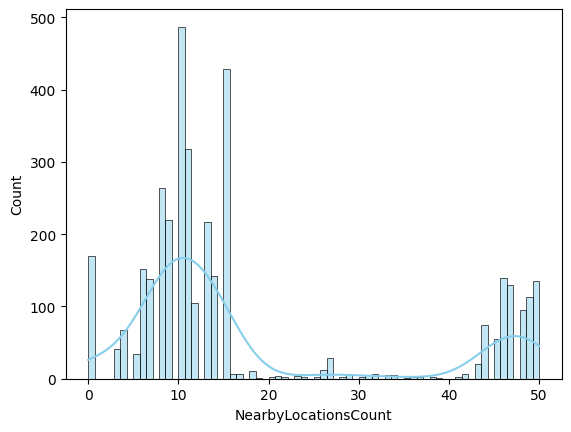

In [94]:
sns.histplot(df['NearbyLocationsCount'], bins=70, color='skyblue', kde=True)

<Axes: ylabel='NearbyLocationsCount'>

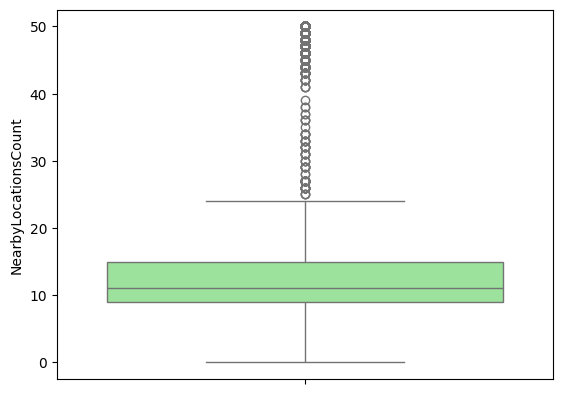

In [95]:
sns.boxplot(df['NearbyLocationsCount'], color='lightgreen')

In [96]:
df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,...,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
0,flat,gls arawali homes,sohna road,0.35,7000.0,500.0,Super Built up area 567(52.68 sq.m.)Built Up a...,2,2,2,...,556.0,500.0,0,0,0,0,0,0,30,6
1,flat,the lions cghs,sector 56,2.05,8541.0,2400.0,Carpet area: 2400 (222.97 sq.m.),4,4,3+,...,NaN,2400.0,0,0,0,0,0,0,49,47
2,flat,dlf new town heights,sector 90,1.25,6476.0,1930.0,Super Built up area 1930(179.3 sq.m.)Built Up ...,3,3,3+,...,1700.0,1500.0,1,0,1,0,0,0,65,6
3,flat,sagar apartment,sector 56,1.45,7250.0,2000.0,Super Built up area 2000(185.81 sq.m.)Built Up...,3,3,3+,...,1900.0,1800.0,1,1,1,0,1,0,166,47
4,flat,sare crescent parc,sector 92,0.66,4977.0,1326.0,Carpet area: 1326 (123.19 sq.m.),3,2,2,...,NaN,1326.0,0,0,0,0,0,1,44,8
